In [1]:
import numpy as np
import matplotlib as mpl
from math import cos
import random
rval = lambda x: random.randint(0,1000)/1000

In [2]:
from poset import HasseDiagram

from pdadic import NAryTree as _NAryTree
from pdadic import QTreeDiagonalOperator
from pdadic import QTreeMap
from pdadic.examples import PowerKernelOperator
from pdadic.ploting import HeatMapDiscussion
from pdadic.ploting import show

In [3]:
mpl.rcParams["text.usetex"] = True
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = "16"
mpl.rcParams["text.latex.preamble"] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
\usepackage{bm}
\usepackage{lmodern}  % Optional: for better scaling of Computer Modern
"""

In [4]:
class InstancesCounter:
    _COUNT = 0

    def __init__(self, *args, **kwargs):
        InstancesCounter._COUNT += 1
        self._thiscounter = self._COUNT

        super().__init__(*args, **kwargs)

    @classmethod
    def reset(cls):
        cls._COUNT = 0

    def __repr__(self):
        repstring = super().__repr__()
        
        return f"[{chr(64 + self._thiscounter)}]" + repstring


class NAryTree(InstancesCounter, _NAryTree):
    pass



In [5]:

# tree1 = NAryTree(3, 5)
# tree2 = NAryTree(3, 5)
# tree3 = NAryTree(3, 5)


treeA = NAryTree(3,5)
treeB = NAryTree(3,5)

treeC = NAryTree(3,5)
treeD = NAryTree(3,5)
treeE = NAryTree(3,5)

treeF = NAryTree(3,5)
treeG = NAryTree(3,5)
treeH = NAryTree(3,5)


# hd = HasseDiagram.from_relations([(tree2, tree1), (tree3, tree1)])


hd = HasseDiagram.from_relations([
    (treeA, treeC),
    (treeA, treeD),
    (treeA, treeE),

    (treeB, treeC),
    (treeB, treeE),

    (treeC, treeF),
    (treeC, treeG),

    (treeD, treeG),
    (treeD, treeH),

    (treeE, treeG),
    (treeE, treeH),
])

# hd.mu[tree1] = 1.0
# hd.mu[tree2] = 1.0

In [6]:

func = lambda x: 4 * np.exp(-2**4 * (x - 0.5)**2)
# func = lambda x: 1 - abs(x-0.5)/5

k = 32

meanA, funcA = QTreeMap.from_function(treeA, func).kill_mean()
meanB, funcB = QTreeMap.from_function(treeB, func).kill_mean()

meanC, funcC = QTreeMap.from_function(treeC, rval).kill_mean()
meanD, funcD = QTreeMap.from_function(treeD, rval).kill_mean()
meanE, funcE = QTreeMap.from_function(treeE, rval).kill_mean()
meanF, funcF = QTreeMap.from_function(treeF, lambda x:0).kill_mean()
meanG, funcG = QTreeMap.from_function(treeG, lambda x:0).kill_mean()
meanH, funcH = QTreeMap.from_function(treeH, lambda x:0).kill_mean()

# mean1, func1 = QTreeMap.from_function(tree1, func).kill_mean()
# mean2, func2 = QTreeMap.from_function(tree2, lambda x: 0 * func(x)).kill_mean()
# mean3, func3 = QTreeMap.from_function(tree3, lambda x: 1).kill_mean()

# initial_values = {
#     tree1: func1,
#     tree2: func2,
#     tree3: func3
# }

# f0 = {
#     tree1: mean1,
#     tree2: mean2,
#     tree3: mean3,
# }

initial_values = {
    treeA: funcA,
    treeB: funcB,
    treeC: funcC,
    treeD: funcD,
    treeE: funcE,
    treeF: funcF,
    treeG: funcG,
    treeH: funcH,
}

f0 = {
    treeA: meanA,
    treeB: meanB,
    treeC: meanC,
    treeD: meanD,
    treeE: meanE,
    treeF: meanF,
    treeG: meanG,
    treeH: meanH,
}


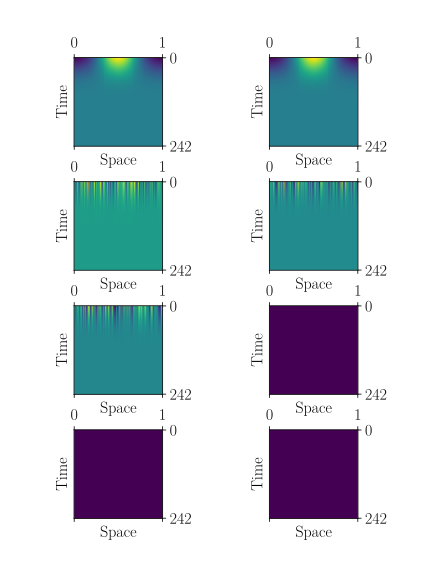

In [7]:
T = 18.0

# elements = hd.linear_extension()
ops = dict()
for tree in hd.linear_extension():
    op = PowerKernelOperator(qtree=tree, alpha=0.8)
    evs = op.eigenvalues
    
    for i in range(len(evs)):
        evs += (len(hd.upset(tree)) - 1) / hd.upmu(tree)

    ops[tree] = (QTreeDiagonalOperator(tree, evs))

ts = T * QTreeDiagonalOperator.get_geometric_ts(243, r=0.02)

images = []
for tree in hd.linear_extension():
    images.append(
        [list(i) for i in ops[tree].get_slices(initial_values[tree], ts)]
    )

disucussion = HeatMapDiscussion(images).single()
show(disucussion)


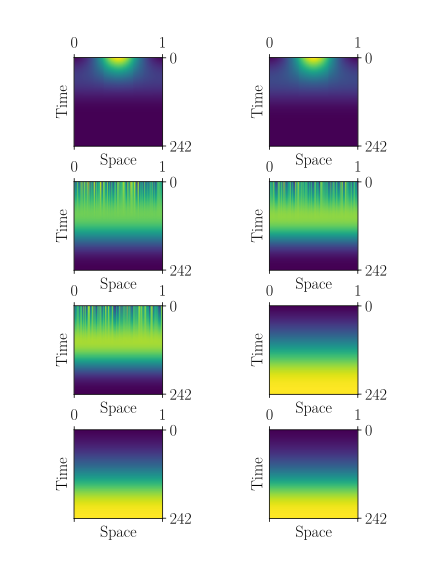

In [8]:
# initial mass at 0

for i, t in enumerate(ts):
    ft = hd.cauchy_solution(t, f0, kernel="down", sign=1)

    for k, tree in enumerate(hd.linear_extension()):
        images[k][i] =  [ft[tree] + pixel for pixel in images[k][i]]

disucussion = HeatMapDiscussion(images).single()
show(disucussion)


[A]3AryTree(height=5, leaves=243)
[B]3AryTree(height=5, leaves=243)
[D]3AryTree(height=5, leaves=243)
[C]3AryTree(height=5, leaves=243)
[E]3AryTree(height=5, leaves=243)
[F]3AryTree(height=5, leaves=243)
[H]3AryTree(height=5, leaves=243)
[G]3AryTree(height=5, leaves=243)


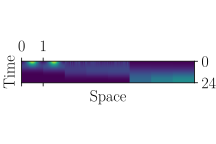

In [9]:
one_image = []



for t in range(len(images[0])):
    one_image.append(
        sum((images[i][t] for i in range(len(initial_values))), start = [])
        # images[0][t] + images[1][t]
    )

disucussion = HeatMapDiscussion([one_image]).single()
print("\n".join(str(i) for i in hd.linear_extension()))
show(disucussion)
